In [2]:
# Load the same prepared tables from the Data Lead's module
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the local project, or download it when running in Colab.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'src/features.py').is_file()),
            Path.cwd() / 'Build-Week-2-Hotel-overbooking-forecast')
if not ROOT.exists():
    import subprocess
    subprocess.run(['git', 'clone', '--depth', '1',
                    'https://github.com/MohitPasupuleti/Build-Week-2-Hotel-overbooking-forecast.git',
                    str(ROOT)], check=True)

sys.path.insert(0, str(ROOT / 'src'))
import contract
import features
import data
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# The CSV is ignored by Git, so download it on a fresh runtime.
globals().update(features.prepare_state(data_path=data.download(ROOT / 'data')))


2015-07-01 00:00:00
2017-08-31 00:00:00
Training median for children: 0.0


# Feature Eligibility (team decision)

Only predictors known **when the booking is made** may enter the final model. The features below need a decision from the Data Lead, challenged by the Build Lead. Change `to_confirm` and `USE_UNCONFIRMED` after that decision. The sensitivity check shows how much the result depends on them.

In [3]:
# Features still to be confirmed as booking-time fields (edit after the team decision)
to_confirm = ['market_segment', 'distribution_channel', 'customer_type', 'reserved_room_type',
              'stays_in_week_nights', 'stays_in_weekend_nights']
confirmed = [f for f in selected_features if f not in to_confirm]
USE_UNCONFIRMED = True    # False = use confirmed features only

In [4]:
# Preprocessing for any feature list (fit on training only)
def make_prep(cols):
    cat = [c for c in categorical_features if c in cols]
    num = [c for c in numerical_features if c in cols]
    bina = [c for c in binary_features if c in cols]
    return ColumnTransformer([
        ('cat', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='Unknown')),
                          ('enc', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat),
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num),
        ('bin', 'passthrough', bina)])

In [5]:
# Imports for models and metrics
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import brier_score_loss, roc_auc_score, RocCurveDisplay
from sklearn.calibration import calibration_curve

In [6]:
# Sensitivity check: all selected features vs confirmed features only
for name, cols in {'All selected': selected_features, 'Confirmed only': confirmed}.items():
    m = Pipeline([('prep', make_prep(cols)), ('clf', LogisticRegression(max_iter=1000))]).fit(X_train[cols], y_train)
    p = m.predict_proba(X_validation[cols])[:, 1]
    print(name, '| Brier:', round(brier_score_loss(y_validation, p), 4), '| ROC-AUC:', round(roc_auc_score(y_validation, p), 4))

All selected | Brier: 0.1969 | ROC-AUC: 0.7085
Confirmed only | Brier: 0.2162 | ROC-AUC: 0.6651


In [7]:
# Final feature list used by all models
final_features = selected_features if USE_UNCONFIRMED else confirmed
print(len(final_features), 'features:', final_features)

12 features: ['hotel', 'lead_time', 'arrival_month', 'market_segment', 'distribution_channel', 'customer_type', 'reserved_room_type', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'stays_in_week_nights', 'stays_in_weekend_nights']


In [8]:
# New booking-time features built from existing columns
def add_features(X, frame):
    X = X.copy()
    X['arrival_dow'] = frame['arrival_date'].dt.dayofweek.astype(str)
    X['lead_time_log'] = np.log1p(frame['lead_time'])
    X['has_weekend_stay'] = (frame['stays_in_weekend_nights'] > 0).astype(int)
    return X

if 'arrival_dow' not in final_features:      # safe to re-run
    X_train = add_features(X_train, train_bookings)
    X_validation = add_features(X_validation, validation_bookings)
    X_test = add_features(X_test, test_bookings)
    categorical_features.append('arrival_dow')
    numerical_features.append('lead_time_log')
    binary_features.append('has_weekend_stay')
    final_features = final_features + ['arrival_dow', 'lead_time_log', 'has_weekend_stay']

print(final_features)

['hotel', 'lead_time', 'arrival_month', 'market_segment', 'distribution_channel', 'customer_type', 'reserved_room_type', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'stays_in_week_nights', 'stays_in_weekend_nights', 'arrival_dow', 'lead_time_log', 'has_weekend_stay']


# Models

Three probability methods are compared with the same nightly pipeline:
1. **Lookup table:** training cancellation rate by hotel, market segment and lead-time group (no learning).
2. **Logistic Regression:** tuned on validation.
3. **Gradient Boosting:** a second learned model, tuned on validation.

Tuning picks the setting with the lowest **Brier score** on the validation period, because the nightly forecast adds probabilities together.

In [9]:
# Scores used everywhere: accuracy (threshold 0.5), Brier score, ROC-AUC
def score(y, p):
    return {'accuracy': ((p >= .5) == y).mean(), 'brier': brier_score_loss(y, p), 'roc_auc': roc_auc_score(y, p)}

In [10]:
# Lookup table: cancellation rate by hotel, market segment and lead-time group
bins = [-1, 30, 90, 180, 10**6]
keys = lambda f: f[['hotel', 'market_segment']].assign(lt=pd.cut(f['lead_time'], bins, labels=False))
train_rate = train_bookings.groupby('hotel')['is_canceled'].mean()
grp = train_bookings.groupby(pd.MultiIndex.from_frame(keys(train_bookings)))['is_canceled'].agg(['mean', 'count'])
lookup = grp['mean'].where(grp['count'] >= 30)      # small groups fall back to the hotel rate

In [11]:
# Lookup probability for any bookings table
def lookup_prob(f):
    p = pd.Series(lookup.reindex(pd.MultiIndex.from_frame(keys(f))).to_numpy(), index=f.index)
    return p.fillna(f['hotel'].map(train_rate)).clip(0, 1).to_numpy()

In [12]:
# Tune Logistic Regression: try several regularisation strengths C
lr_models, rows = {}, []
for C_ in [0.003, 0.01, 0.03, 0.1, 1, 10]:
    lr_models[C_] = Pipeline([('prep', make_prep(final_features)), ('clf', LogisticRegression(C=C_, max_iter=1000))]).fit(X_train[final_features], y_train)
    rows.append({'C': C_, **score(y_validation, lr_models[C_].predict_proba(X_validation[final_features])[:, 1])})
lr_tuning = pd.DataFrame(rows).set_index('C')
lr_tuning.round(4)

,accuracy,brier,roc_auc
C,,,
0.003,0.6975,0.1934,0.7285
0.010,0.7032,0.1923,0.7326
0.030,0.7010,0.1934,0.7322
0.100,0.7009,0.1946,0.7307
1.000,0.6977,0.1953,0.7300
10.000,0.6978,0.1953,0.7299


In [13]:
# Tune Gradient Boosting: learning rate, tree depth and regularisation
gb_models, rows = {}, []
for lr_ in [0.03, 0.05, 0.1]:
    for depth in [3, 5, 7]:
        for l2 in [0, 1]:
            gb = HistGradientBoostingClassifier(learning_rate=lr_, max_depth=depth, l2_regularization=l2,
                                                max_iter=200, early_stopping=False, random_state=42)
            gb_models[(lr_, depth, l2)] = Pipeline([('prep', make_prep(final_features)),
                                                    ('clf', gb)]).fit(X_train[final_features], y_train)
            rows.append({'learning_rate': lr_, 'max_depth': depth, 'l2': l2,
                         **score(y_validation, gb_models[(lr_, depth, l2)].predict_proba(X_validation[final_features])[:, 1])})
gb_tuning = pd.DataFrame(rows).set_index(['learning_rate', 'max_depth', 'l2'])
gb_tuning.sort_values('brier').round(4)

accuracy   brier  roc_auc
learning_rate max_depth l2                           
0.03          5         1     0.7142  0.1860   0.7461
              3         1     0.7162  0.1861   0.7445
                        0     0.7162  0.1864   0.7437
              5         0     0.7153  0.1865   0.7454
0.05          3         0     0.7179  0.1870   0.7424
                        1     0.7115  0.1874   0.7417
              5         1     0.7099  0.1904   0.7384
0.10          3         0     0.7092  0.1906   0.7367
                        1     0.7102  0.1908   0.7361
0.03          7         1     0.6999  0.1912   0.7371
0.05          5         0     0.7100  0.1914   0.7372
0.03          7         0     0.6992  0.1924   0.7346
0.05          7         1     0.7004  0.1945   0.7343
                        0     0.7011  0.1959   0.7322
0.10          5         1     0.6994  0.2012   0.7260
                        0     0.6990  0.2028   0.7211
              7         0     0.6939  0.2051   0.7242
                        1     0.6970  0.2064   0.7202

In [14]:
# Keep the best setting of each model (lowest validation Brier score)
models = {'Logistic Regression': lr_models[lr_tuning['brier'].idxmin()],
          'Gradient Boosting': gb_models[gb_tuning['brier'].idxmin()]}
print('Best C:', lr_tuning['brier'].idxmin(), '| Best GB setting:', gb_tuning['brier'].idxmin())

Best C: 0.01 | Best GB setting: (np.float64(0.03), np.int64(5), np.int64(1))


# Model Validation (train vs validation)

Accuracy is shown because the client mentioned it, but it is not the decision metric: always predicting "not cancelled" already gives about 64% accuracy. A large gap between train and validation scores would mean overfitting.

In [15]:
# Probabilities for every model on train and validation
P_train = {'Lookup table': lookup_prob(train_bookings)}
P_val = {'Lookup table': lookup_prob(validation_bookings)}
for name, m in models.items():
    P_train[name] = m.predict_proba(X_train[final_features])[:, 1]
    P_val[name] = m.predict_proba(X_validation[final_features])[:, 1]

In [16]:
# Accuracy, Brier score and ROC-AUC: train vs validation
pd.DataFrame([{'model': n, 'set': s, **score(y, P[n])}
              for n in P_val for s, P, y in (('train', P_train, y_train), ('validation', P_val, y_validation))]).round(4)

,model,set,accuracy,brier,roc_auc
0,Lookup table,train,0.7238,0.1835,0.7574
1,Lookup table,validation,0.6664,0.2052,0.6969
2,Logistic Regression,train,0.8007,0.1460,0.8285
3,Logistic Regression,validation,0.7032,0.1923,0.7326
4,Gradient Boosting,train,0.8259,0.1238,0.8787
5,Gradient Boosting,validation,0.7142,0.1860,0.7461


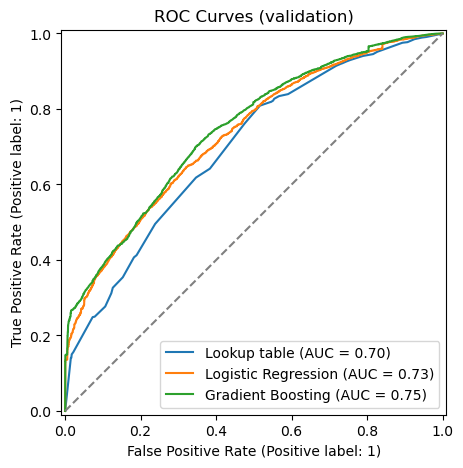

In [17]:
# ROC curves (validation)
ax = plt.subplots(figsize=(6, 5))[1]
for name, p in P_val.items():
    RocCurveDisplay.from_predictions(y_validation, p, name=name, ax=ax)
ax.plot([0, 1], [0, 1], '--', color='grey'); plt.title('ROC Curves (validation)'); plt.show()

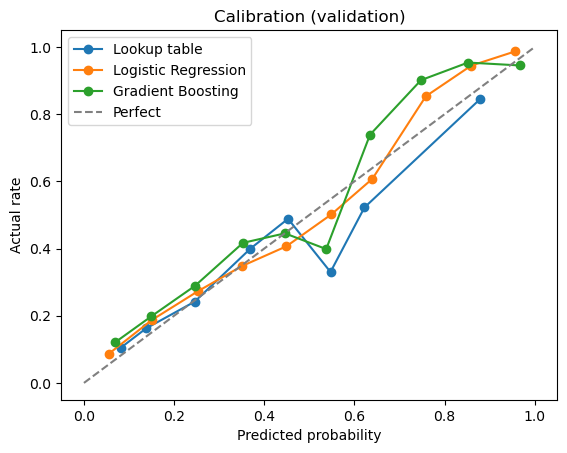

In [18]:
# Calibration curves (validation)
for name, p in P_val.items():
    a, b = calibration_curve(y_validation, p, n_bins=10)
    plt.plot(b, a, marker='o', label=name)
plt.plot([0, 1], [0, 1], '--', color='grey', label='Perfect')
plt.xlabel('Predicted probability'); plt.ylabel('Actual rate'); plt.title('Calibration (validation)'); plt.legend(); plt.show()

# Nightly Forecast

In [19]:
# One row per hotel-night for every model: book, expected (mu), spread (sigma), stay_value
N_val = {name: contract.nightly_table(validation_bookings, p) for name, p in P_val.items()}
N_val['Logistic Regression'].head()

book  cancelled   expected    spread  stay_value
hotel      arrival_date                                                  
City Hotel 2016-07-01     141         68  72.126141  5.403078  319.747589
           2016-07-02      80         33  34.261233  4.219634  397.106875
           2016-07-03      85         21  34.252893  4.356836  478.769529
           2016-07-04      92         30  32.743170  4.199173  440.365543
           2016-07-05      74         14  28.963622  3.960752  405.705811

In [20]:
# Check: total expected vs actual cancellations per model
pd.DataFrame({n: {'expected': t['expected'].sum(), 'actual': t['cancelled'].sum()} for n, t in N_val.items()}).T.round(0)

,expected,actual
Lookup table,10809.0,10894.0
Logistic Regression,10802.0,10894.0
Gradient Boosting,9846.0,10894.0


# Overbooking Rules

All rules give whole rooms, never below 0 and never above the night's bookings.

| Rule | Formula | Setting tuned on validation |
|---|---|---|
| **Client flat rule** | k = max(0, floor(bookings x hotel cancellation rate - safety_rooms)) | `safety_rooms` |
| **ML uncertainty buffer** | k = max(0, floor(mu - z x sigma)) | `z` |
| **ML constant rooms buffer** | k = max(0, floor(mu - b)) | `b` rooms |

The flat rule subtracts a **fixed number of rooms**, the same on every night.

In [21]:
# One function for all three rules
def k_of(n, kind, v):
    if kind == 'flat':
        k = n['book'] * n.index.get_level_values('hotel').map(train_rate).to_numpy() - v
    elif kind == 'z':
        k = n['expected'] - v * n['spread']
    else:
        k = n['expected'] - v
    return pd.Series(np.floor(k), index=n.index).clip(lower=0).clip(upper=n['book']).astype(int)

In [22]:
# Settings to try
grids = {'flat': range(0, 41), 'z': np.arange(0, 4.01, .25), 'b': range(0, 31)}
FLAT = 'Client flat rule'

In [23]:
# Score every model, rule and setting on the validation period with the contract
rows = []
for name, n in N_val.items():
    for kind in ('z', 'b'):
        rows += [{'model': name, 'rule': kind, 'value': v, **contract.night_cost(n, k_of(n, kind, v))} for v in grids[kind]]
rows += [{'model': FLAT, 'rule': 'flat', 'value': v, **contract.night_cost(N_val['Lookup table'], k_of(N_val['Lookup table'], 'flat', v))} for v in grids['flat']]
search = pd.DataFrame(rows)

In [24]:
# Cheapest setting that meets the walk ceiling, for each model and rule
safe = search[search['ceiling_met']]
best = safe.sort_values('cost_eur').groupby(['model', 'rule']).head(1).reset_index(drop=True)
best[['model', 'rule', 'value', 'cost_eur', 'empty_rooms', 'walked_guests', 'walks_per_1000']]

,model,rule,value,cost_eur,empty_rooms,walked_guests,walks_per_1000
0,Gradient Boosting,z,2.25,1816812.47,4279,167,8.95
1,Logistic Regression,z,3.25,2000528.93,4778,180,9.65
2,Gradient Boosting,b,10.00,2043784.24,4711,170,9.11
3,Logistic Regression,b,16.00,2270504.44,5267,163,8.74
4,Client flat rule,flat,16.00,2414409.40,5532,169,9.06
5,Lookup table,b,26.00,3059908.23,7261,185,9.92


In [25]:
# Select ONE policy: the cheapest safe one on validation, then freeze it
assert len(best) > 0, 'No safe setting found'
selected = best.iloc[0]
print('Selected policy:', selected['model'], '| rule:', selected['rule'], '| setting:', selected['value'])

Selected policy: Gradient Boosting | rule: z | setting: 2.25
